# LDA / التحليل التمييزي الخطي

The built-in wine dataset contains three classes and 13 measurements. Use the training labels to find two directions, then classify the wine with those two coordinates. Run the cells in order with **Shift + Enter**.

تحتوي بيانات النبيذ المضمّنة على ثلاث فئات و١٣ قياسًا. استخدم تسميات التدريب لإيجاد اتجاهَين، ثم صنّف النبيذ باستخدام هذين الإحداثيَين. شغّل الخلايا بالترتيب باستخدام **Shift + Enter**.

## Fit and check / درّب واختبر

The training split fits the scaler, the projection and logistic regression. The test split measures how often the pipeline predicts the correct class.

يستخدم خط المعالجة بيانات التدريب لضبط المقاييس وحساب الإسقاط وتدريب الانحدار اللوجستي. وتقيس بيانات الاختبار كم مرّة يتوقّع الخط الفئة الصحيحة.

In [1]:
from sklearn.datasets import load_wine
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
model = Pipeline([
    ("scale", StandardScaler()),
    ("reduce", LinearDiscriminantAnalysis(n_components=2)),
    ("classify", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(f"Test accuracy after reduction: {accuracy_score(y_test, predictions):.1%}")
print("Confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_test, predictions, labels=model.classes_))

Test accuracy after reduction: 97.8%
Confusion matrix (rows = true, columns = predicted):
[[15  0  0]
 [ 0 18  0]
 [ 0  1 11]]


## See it / شاهد النتيجة

LDA chooses axes that separate the training classes. The plot shows how the held-out classes land on those axes. The shading shows the classifier's predicted class at each position.

يختار التحليل التمييزي محاور تفصل فئات التدريب. يوضّح الرسم أين تقع فئات الاختبار على تلك المحاور. يوضّح لون الخلفية الفئة التي يتوقّعها المصنّف في كل موضع.

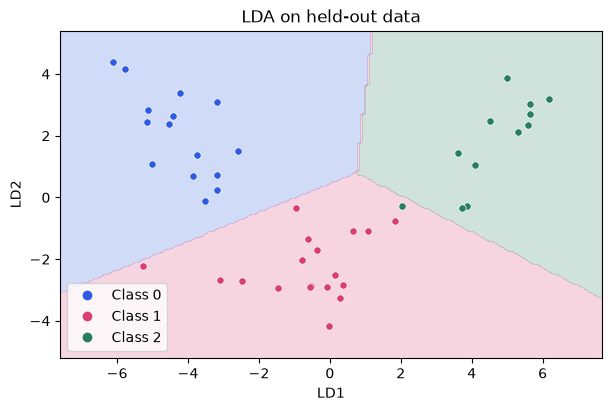

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

colors = ["#2d5be3", "#d93d74", "#287f60"]
classes = model.classes_
region_colors = ListedColormap(colors[:len(classes)])
legend = [
    Line2D([], [], marker="o", linestyle="none", color=colors[i], label=f"Class {name}")
    for i, name in enumerate(classes)
]

def draw_regions(ax, data, labels, classifier, title, x_label, y_label):
    lo, hi = data.min(axis=0), data.max(axis=0)
    padding = np.maximum((hi - lo) * 0.12, 0.05)
    x = np.linspace(lo[0] - padding[0], hi[0] + padding[0], 160)
    y = np.linspace(lo[1] - padding[1], hi[1] + padding[1], 160)
    xx, yy = np.meshgrid(x, y)
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    regions = np.searchsorted(classes, classifier.predict(grid)).reshape(xx.shape)
    ax.contourf(xx, yy, regions, levels=np.arange(len(classes) + 1) - 0.5,
                cmap=region_colors, alpha=0.22)
    for i, name in enumerate(classes):
        points = data[labels == name]
        ax.scatter(points[:, 0], points[:, 1], color=colors[i],
                   edgecolor="white", linewidth=0.5, s=28)
    ax.set(title=title, xlabel=x_label, ylabel=y_label)

projected = model[:-1].transform(X_test)
logistic = model.named_steps["classify"]

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
draw_regions(ax, projected, y_test, logistic, "LDA on held-out data", "LD1", "LD2")
ax.legend(handles=legend)
plt.show()